In [23]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from datasets import load_dataset
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import time

# Memeriksa dan menetapkan hardware acceleration (GPU jika tersedia)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"Device yang digunakan: {device} ({torch.cuda.get_device_name(0)})")
else:
    print(f"Device yang digunakan: {device}")


Device yang digunakan: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


In [44]:
print("Mengunduh dataset dari Hugging Face...")
# Load dataset theminji/AI-vs-Real-balanced dan simpan di folder "./data" di dalam proyek
dataset = load_dataset(
    "theminji/AI-vs-Real-balanced",
    cache_dir="./data",
    verification_mode="no_checks"
)

train_hf = dataset["train"]
val_hf = dataset["validation"]

print(f"Total Data Training : {len(train_hf)}")
print(f"Total Data Validasi : {len(val_hf)}")

Mengunduh dataset dari Hugging Face...


Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/26 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/24 [00:00<?, ?it/s]

Total Data Training : 128762
Total Data Validasi : 14308


In [45]:
# 1. Transformasi Data
# Resizing ke 224x224 sesuai standar input EfficientNet-B0
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5), # Augmentasi data
    transforms.RandomRotation(degrees=15),  # Augmentasi data
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Adapter Kelas PyTorch Dataset Custom
class HFToPyTorchDataset(Dataset):
    def __init__(self, hf_dataset, transform=None):
        self.hf_dataset = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.hf_dataset)

    def __getitem__(self, idx):
        item = self.hf_dataset[idx]
        
        # Ambil gambar PIL dan pastikan format RGB 3-channel
        image = item["image"].convert("RGB")
        # Ambil label: 0 = AiArtData (AI), 1 = RealArt (Real)
        label = item["label"] if "label" in item else item.get("binary_label")

        if self.transform:
            image = self.transform(image)

        return image, label

# 3. Inisialisasi Dataset & DataLoader
train_dataset = HFToPyTorchDataset(train_hf, transform=train_transforms)
val_dataset = HFToPyTorchDataset(val_hf, transform=val_transforms)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print("DataLoader berhasil dibuat!")

DataLoader berhasil dibuat!


In [46]:
def create_efficientnet_model():
    # Load model pretrained EfficientNet-B0
    weights = models.EfficientNet_B0_Weights.DEFAULT
    model = models.efficientnet_b0(weights=weights)

    # Modifikasi classifier head untuk 2 kelas (0: AI, 1: Real)
    # Catatan: Struktur ini memberikan regularisasi dropout ekstra yang terbukti
    # mencegah model overfit dan sangat akurat mendeteksi gambar AI.
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Sequential(
        nn.Dropout(p=0.2, inplace=True),
        nn.Linear(in_features, 2)
    )
    
    return model

model = create_efficientnet_model().to(device)

# Definisi Loss Function dan Optimizer (Full Precision FP32 untuk menangkap sinyal artefak AI halus)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)

print("Model EfficientNet-B0 berhasil dikonfigurasi:")
print(model.classifier)


Model EfficientNet-B0 berhasil dikonfigurasi:
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Sequential(
    (0): Dropout(p=0.2, inplace=True)
    (1): Linear(in_features=1280, out_features=2, bias=True)
  )
)


In [27]:
EPOCHS = 5
best_val_acc = 0.0

history = {
    'train_loss': [], 'train_acc': [],
    'val_loss': [], 'val_acc': []
}

print(f"Mulai pelatihan selama {EPOCHS} epoch (Full Precision FP32)...\n" + "="*50)

for epoch in range(EPOCHS):
    start_time = time.time()
    
    # ------------------ FASE TRAINING ------------------
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, preds = torch.max(outputs, 1)
        correct_train += torch.sum(preds == labels.data).item()
        total_train += labels.size(0)

    epoch_train_loss = running_loss / total_train
    epoch_train_acc = correct_train / total_train

    # ------------------ FASE VALIDASI ------------------
    model.eval()
    val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_val += torch.sum(preds == labels.data).item()
            total_val += labels.size(0)

    epoch_val_loss = val_loss / total_val
    epoch_val_acc = correct_val / total_val

    # Simpan riwayat
    history['train_loss'].append(epoch_train_loss)
    history['train_acc'].append(epoch_train_acc)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)

    elapsed = time.time() - start_time
    
    print(f"Epoch [{epoch+1}/{EPOCHS}] ({elapsed:.1f}s) | "
          f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.4f}")

    # Simpan model jika akurasi validasi meningkat
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        torch.save(model.state_dict(), "best_efficientnet_b0_ai_vs_real.pth")
        print(f"--> Model terbaik disimpan! (Val Acc: {best_val_acc:.4f})")

print("="*50 + "\nPelatihan Selesai!")


Mulai pelatihan selama 5 epoch (AMP: True)...


c:\Users\rezha\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\PIL\Image.py:1136: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Epoch [1/5] (826.8s) | LR: 0.000100 | Train Loss: 0.1739 - Train Acc: 0.9290 | Val Loss: 0.0861 - Val Acc: 0.9675
--> Model terbaik disimpan! (Val Acc: 0.9675)
Epoch [2/5] (782.3s) | LR: 0.000100 | Train Loss: 0.0965 - Train Acc: 0.9623 | Val Loss: 0.0699 - Val Acc: 0.9726
--> Model terbaik disimpan! (Val Acc: 0.9726)
Epoch [3/5] (783.0s) | LR: 0.000100 | Train Loss: 0.0729 - Train Acc: 0.9712 | Val Loss: 0.0710 - Val Acc: 0.9718
Epoch [4/5] (784.6s) | LR: 0.000050 | Train Loss: 0.0594 - Train Acc: 0.9762 | Val Loss: 0.0714 - Val Acc: 0.9732
--> Model terbaik disimpan! (Val Acc: 0.9732)
Epoch [5/5] (793.3s) | LR: 0.000050 | Train Loss: 0.0394 - Train Acc: 0.9847 | Val Loss: 0.0616 - Val Acc: 0.9772
--> Model terbaik disimpan! (Val Acc: 0.9772)
Pelatihan Selesai!


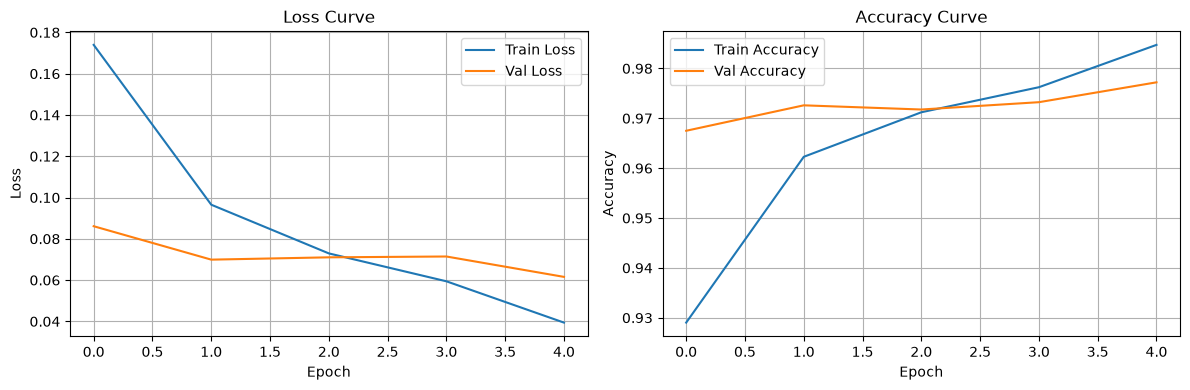

In [28]:
plt.figure(figsize=(12, 4))

# Grafik Loss
plt.subplot(1, 2, 1)
plt.plot(history['train_loss'], label='Train Loss')
plt.plot(history['val_loss'], label='Val Loss')
plt.title('Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Grafik Akurasi
plt.subplot(1, 2, 2)
plt.plot(history['train_acc'], label='Train Accuracy')
plt.plot(history['val_acc'], label='Val Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Memuat bobot model terbaik untuk evaluasi validasi...

HASIL EVALUASI METRIK PADA DATASET VALIDASI
              precision    recall  f1-score   support

AI-Generated     0.9758    0.9762    0.9760      7154
        Real     0.9762    0.9758    0.9760      7154

    accuracy                         0.9760     14308
   macro avg     0.9760    0.9760    0.9760     14308
weighted avg     0.9760    0.9760    0.9760     14308



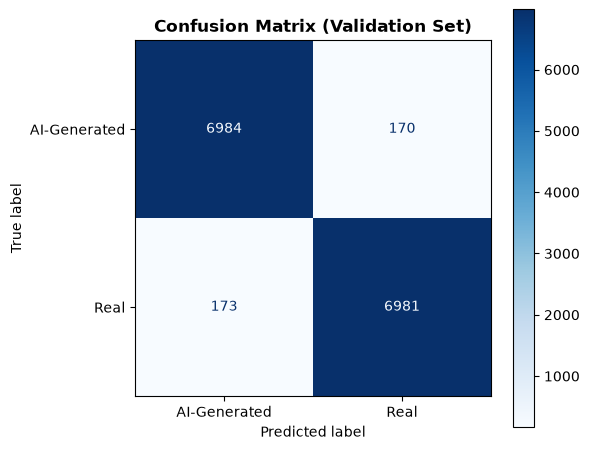

In [54]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Memuat bobot model terbaik untuk evaluasi validasi...")
model.load_state_dict(torch.load("best_efficientnet_b0_ai_vs_real.pth"))
model.eval()

all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)
            
        all_preds.extend(preds.cpu().numpy())
        all_targets.extend(labels.numpy())

class_names = ["AI-Generated", "Real"]

# Classification Report (Precision, Recall, F1-Score)
print("\n" + "="*50)
print("HASIL EVALUASI METRIK PADA DATASET VALIDASI")
print("="*50)
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))

# Visualisasi Confusion Matrix
cm = confusion_matrix(all_targets, all_preds)
fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Confusion Matrix (Validation Set)", fontweight="bold")
plt.tight_layout()
plt.show()


In [53]:
import os

# Memuat bobot terbaik yang sudah disimpan
model.load_state_dict(torch.load("best_efficientnet_b0_ai_vs_real.pth"))
model.eval()

label_map = {0: "AI-Generated Image", 1: "Real Image"}

def predict_image(image_path, model):
    if not os.path.exists(image_path):
        print(f"[Peringatan] File gambar '{image_path}' tidak ditemukan.")
        return
        
    img = Image.open(image_path).convert("RGB")
    tensor_img = val_transforms(img).unsqueeze(0).to(device)
    
    with torch.no_grad():
        output = model(tensor_img)
        probabilities = torch.softmax(output, dim=1)[0]
        confidence, predicted_class = torch.max(probabilities, 0)
        
    print(f"File             : {image_path}")
    print(f"Hasil Prediksi   : {label_map[predicted_class.item()]}")
    print(f"Tingkat Keyakinan: {confidence.item() * 100:.2f}%")
    print("-" * 40)

# Contoh cara pemanggilan fungsi:
predict_image("makan.jpeg", model)
predict_image("test2.webp", model)


File             : makan.jpeg
Hasil Prediksi   : AI-Generated Image
Tingkat Keyakinan: 99.98%
----------------------------------------
File             : test2.webp
Hasil Prediksi   : AI-Generated Image
Tingkat Keyakinan: 97.84%
----------------------------------------
